# Tarea 21: Práctica KNN  

### Carga de librearias y datos

In [1]:
# Load libraries for this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the data
data_frame = pd.read_csv('recursos_humanos.csv')
data_frame.sample(5)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
13567,0.53,0.70,4,223,3,0,0,0,sales,low
2601,0.76,0.80,5,229,2,0,0,0,marketing,medium
13162,0.92,0.66,4,113,3,0,0,0,technical,low
12603,0.83,0.90,5,245,5,0,1,0,product_mng,low
8966,0.51,0.91,4,194,2,0,0,0,technical,medium


Verificación de nulos en el data set

In [4]:
data_frame.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


### Codificación de variables categóricas

Las variables categoricas encontradas en los datos son: 'sales' y 'salary', se va a usar la función get_dummies de pandas para remplazarlarlas por valores numéricos.

In [6]:
data_frame_updated = pd.get_dummies(data_frame, columns=['sales', 'salary'], dtype= float)
data_frame_updated.sample(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
8439,0.77,0.50,4,173,2,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
8982,0.47,0.44,5,255,5,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
530,0.40,0.56,2,137,3,0,1,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5858,0.78,0.63,3,192,2,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8583,0.78,0.61,3,227,3,0,0,0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Determinación del equilibrio en los datos

Mediante EDA verificar si la base de datos esta equilibrada:

In [7]:
print(f'{data_frame_updated['left'].value_counts(normalize=True)}')

left
0    0.761917
1    0.238083
Name: proportion, dtype: float64


Con la información mostrada se observa que los datos no estan equilibrados porque el *76.19* se queday el *23.80* se va.

### Modelo predictivo con el método de KNN 

#### Definición de las variables para aplicar el modelo

*Nota*: Antes de comenzar a hacer las operaciones con los datos; a continuación se muestra un análisis de los puestos vs horas trabajadas (con los datos originales) y se puede observar una tendencia de un promedio de horas trabajadas respecto a los que se quedaron. 

In [25]:
has_left = data_frame[data_frame.left == 1]
has_stayed = data_frame[data_frame.left == 0]

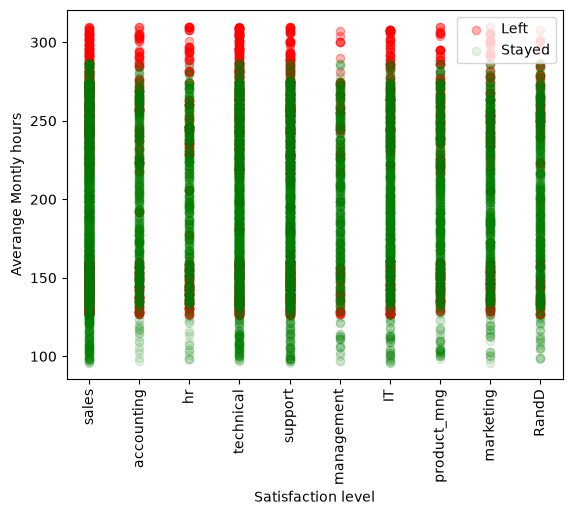

In [26]:
plt.scatter(has_left.sales, has_left.average_montly_hours, color = 'red', label= 'Left', alpha=0.3)
plt.scatter(has_stayed.sales, has_stayed.average_montly_hours, color = 'green', label= 'Stayed', alpha=0.1)
plt.xlabel('Satisfaction level')
plt.xticks(rotation = 90)
plt.ylabel('Averange Montly hours')
plt.legend()
plt.show()

In [27]:
X = data_frame_updated.drop('left', axis= 1)
Y = data_frame_updated['left']   

In [28]:
# Data normalization
x_normalized = (X - np.min(X)) / (np.max(X) - np.min(X))
x_normalized.sample(5) 

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
5568,0.002290,0.002742,0.012903,0.506452,0.006452,0.0,0.0,0.000000,0.003226,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.003226,0.000000
13248,0.002323,0.002742,0.016129,0.764516,0.012903,0.0,0.0,0.000000,0.000000,0.003226,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.003226,0.000000
4186,0.002226,0.002226,0.016129,0.516129,0.009677,0.0,0.0,0.003226,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.003226
774,0.001226,0.001613,0.006452,0.490323,0.009677,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.003226,0.0,0.0,0.003226,0.000000,0.000000
11090,0.002806,0.001677,0.012903,0.451613,0.009677,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.000000,0.000000,0.003226


### Uso del método KNN

In [30]:
# Data for training and test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_normalized, Y, test_size= 0.30, random_state= 1)

### Function para evaluar el método KNN 
Se usan diferentes valores de n = 1, 2, 3 ...

In [ ]:
# get the optimal n for the knn method
from sklearn.neighbors import KNeighborsClassifier

def get_knn(n_neighbor):
    ''' Function to estimate the value of the score for knn values

    Args: 
        n_neighbor: value of the neigbor
    
    Returns:
        A tuple of the neighbor and the score
    '''
    knn = KNeighborsClassifier(n_neighbors=n_neighbor)

    knn.fit(x_train, y_train)

    return n_neighbor, knn.score(x_test, y_test)

# Numbers to evaluate the function, 1 - 20
numbers = np.arange(1, 21)

# Predictions from the function
n_predicitions = [get_knn(n) for n in numbers]

n_predicitions



[(np.int64(1), 0.9455555555555556),
 (np.int64(2), 0.942),
 (np.int64(3), 0.9357777777777778),
 (np.int64(4), 0.9411111111111111),
 (np.int64(5), 0.9342222222222222),
 (np.int64(6), 0.9422222222222222),
 (np.int64(7), 0.9384444444444444),
 (np.int64(8), 0.9402222222222222),
 (np.int64(9), 0.9326666666666666),
 (np.int64(10), 0.9366666666666666),
 (np.int64(11), 0.9317777777777778),
 (np.int64(12), 0.9371111111111111),
 (np.int64(13), 0.9326666666666666),
 (np.int64(14), 0.9351111111111111),
 (np.int64(15), 0.9346666666666666),
 (np.int64(16), 0.9346666666666666),
 (np.int64(17), 0.9313333333333333),
 (np.int64(18), 0.9317777777777778),
 (np.int64(19), 0.9324444444444444),
 (np.int64(20), 0.9331111111111111)]

In [ ]:
n_optimal = max(n_predicitions, key=lambda item: item[1])
print(f'The optiomal value is {n_optimal}')

The optiomal value is (np.int64(1), 0.9455555555555556)


In [51]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=n_optimal[0])

knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

print(f'Score: {knn.score(x_test, y_test)}')

Score: 0.9455555555555556


### Creación de la matriz de confusión

In [52]:
y_pred = prediction
y_true = y_test

# Creation of the confusion matrix
from sklearn.metrics import confusion_matrix
c_matrix = confusion_matrix(y_true, y_pred)
c_matrix

array([[3234,  182],
       [  63, 1021]])

Los resultados que muestra la matriz de confusion expresan los siguiente, basado en los datos de pruebas:
- 3234 personas que se quedaron
- 1021 personas que se fuero y dejaron el empleo
- 182 es un falso positivo, es decir personas que se irian según la predicción pero que se quedaron
- 63 es un falso negativo, personas que se quedarian pero se quedaron

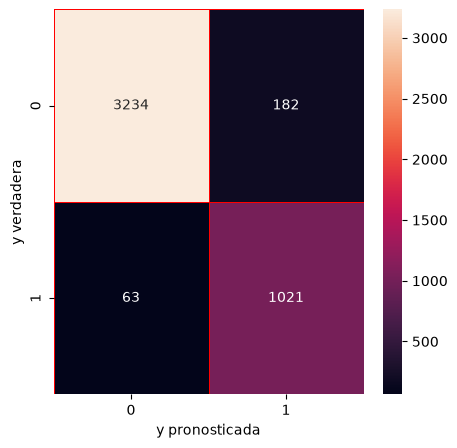

In [53]:
fig, ax = plt.subplots(figsize = (5, 5))

sns.heatmap(c_matrix, annot= True, linewidths= 0.5, linecolor='red', fmt= '.0f', ax=ax)
plt.xlabel('y pronosticada')
plt.ylabel('y verdadera')
plt.show()

### Càlculo de indicadores

In [54]:
correct = c_matrix[0, 0] + c_matrix[1, 1]
incorrect = c_matrix[0, 1] + c_matrix[1, 0]
global_accuracy = correct / (correct + incorrect)
global_accuracy

np.float64(0.9455555555555556)

In [55]:
stayed_accuracy = c_matrix[0, 0] / (c_matrix[0, 0] + c_matrix[1, 0])
stayed_accuracy

np.float64(0.9808917197452229)

In [56]:
left_accuracy = c_matrix[1, 1] / (c_matrix[1, 1] + c_matrix[0, 1])
left_accuracy

np.float64(0.8487115544472152)

### Cálculo de la curva Roc

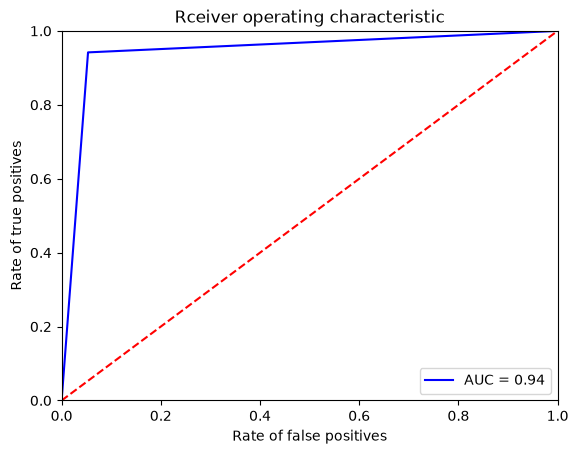

In [57]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_score = knn.predict_proba(x_test)

fpr, tpr, threadhold = roc_curve(y_test, y_score[:, 1])
roc_auc = auc(fpr, tpr)

plt.title('Rceiver operating characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc= 'lower right')
plt.plot([0,1], [0,1], 'r--')
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel('Rate of true positives')
plt.xlabel('Rate of false positives')
plt.show()

El área de bajo la curva de la grafica ROC muestra que tan bueno es e clasificador en general. El valor obtenido es 0.94 se refiere a un valor muy bueno. Esto es bueno porque a pesar de que los datos no estan balanceados el método KNN tiene una buena predicción sobre si un empleado de quedara o abandonara su posición.